<a href="https://colab.research.google.com/github/ayanasanthoshkhan/synthetic-clinical-data-generation/blob/main/notebooks/01_dataset_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Synthetic Clinical Data Generation — Exploratory Data Analysis

## Project Overview
This project compares three generative models:
- TVAE (Variational Autoencoder)
- CTGAN (Conditional Tabular GAN)
- TabDDPM (Tabular Denoising Diffusion Probabilistic Model)

The models will be evaluated on:
1. Statistical Fidelity
2. Machine Learning Utility
3. Privacy Risk

## Dataset
UCI Diabetes 130-US Hospitals (1999–2008)

## Objective of This Notebook
To understand the dataset structure, feature types, missing values,
and readmission target before preprocessing and generative modeling.

## Install required package

In [1]:
%pip install -q ucimlrepo

## Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## Load the dataset

In [3]:
# UCI Diabetes 130-US Hospitals dataset
diabetes = fetch_ucirepo(id=296)

# Features and target
X = diabetes.data.features
y = diabetes.data.targets

# Combine features and target for EDA
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Dataset loaded successfully!
Dataset shape: (101766, 48)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Basic dataset information

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nTarget distribution:")
print(df["readmitted"].value_counts(dropna=False))

Number of rows: 101766
Number of columns: 48

Column names:
['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data types:
object    37
int64     11
Name: count, dtype: int64

Target distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dty

## Missing Value Analysis

Identify missing values, missing-value percentages,
and placeholder values before deciding on preprocessing.

In [5]:
# Missing value analysis

missing_count = df.isna().sum()

missing_percent = (
    missing_count / len(df) * 100
)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Percentage
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


In [6]:
# Identify '?' placeholders

question_marks = (
    df.astype("string")
      .eq("?")
      .sum()
      .sort_values(ascending=False)
)

display(question_marks[question_marks > 0])

,0


## Feature Type and Cardinality Analysis

Examine the data types and number of unique values in each feature
to identify numerical, categorical, and coded clinical variables.

In [7]:
feature_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique(dropna=True),
    "Missing %": (df.isna().mean() * 100).round(2)
})

display(feature_summary)

,Data Type,Unique Values,Missing %
race,object,5,2.23
gender,object,3,0.00
age,object,10,0.00
weight,object,9,96.86
admission_type_id,int64,8,0.00
discharge_disposition_id,int64,26,0.00
admission_source_id,int64,17,0.00
time_in_hospital,int64,14,0.00
payer_code,object,17,39.56
medical_specialty,object,72,49.08


In [8]:
columns_to_inspect = [
    "age",
    "gender",
    "race",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "A1Cresult",
    "max_glu_serum",
    "readmitted"
]

for col in columns_to_inspect:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(f"{'='*50}")

    print(df[col].value_counts(dropna=False).head(20))


Column: age
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

Column: gender
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Column: race
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

Column: admission_type_id
admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10
Name: count, dtype: int64

Column: discharge_disposition_id
discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
25      989
4       815
7       623
23      412
13      399
14      372
28      139
8       108
15       63
24       48
9        21
17       14


## Data quality checks

In [9]:
# ============================================================
# 1. DATA QUALITY CHECKS
# ============================================================

print("Dataset shape:", df.shape)

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nMissing target values:",
      df["readmitted"].isna().sum())

# Constant features
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("\nConstant columns:", constant_columns)

# Missing values summary
print("\nTotal missing cells:", df.isna().sum().sum())

print("\nPercentage of missing cells:",
      round(df.isna().mean().mean() * 100, 2))

# Gender categories
print("\nGender distribution:")
print(df["gender"].value_counts(dropna=False))

# Readmission categories
print("\nReadmission categories:")
print(df["readmitted"].value_counts(dropna=False))

Dataset shape: (101766, 48)

Exact duplicate rows: 0

Missing target values: 0

Constant columns: ['examide', 'citoglipton']

Total missing cells: 374017

Percentage of missing cells: 7.66

Gender distribution:
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Readmission categories:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


## Missing-value visualization

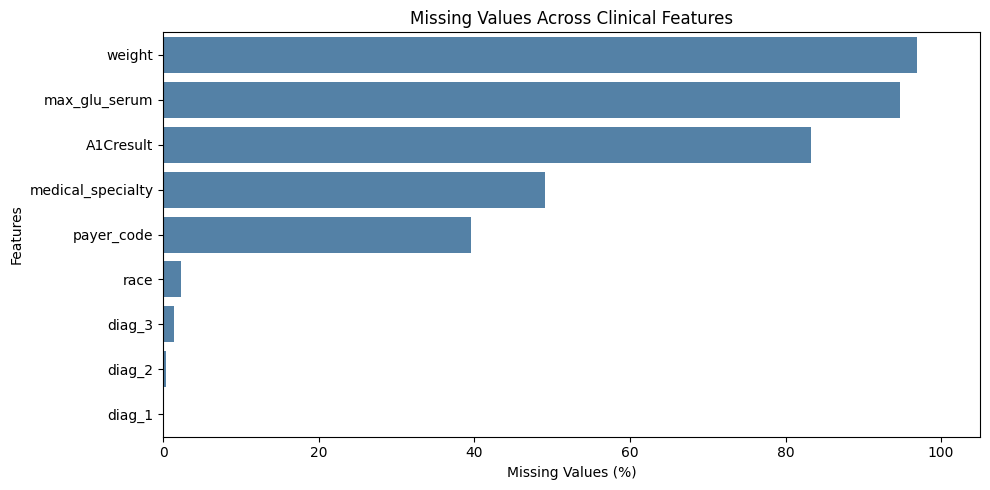

In [10]:
# ============================================================
# 2. MISSING VALUE VISUALIZATION
# ============================================================

missing_pct = (
    df.isna().mean() * 100
).sort_values(ascending=False)

missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index,
    color="steelblue"
)

plt.title("Missing Values Across Clinical Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.xlim(0, 105)

plt.tight_layout()
plt.show()

## Identify numerical and categorical variables

In [11]:
# ============================================================
# 3. FEATURE TYPE IDENTIFICATION
# ============================================================

target_column = "readmitted"

# Integer-coded clinical categories
coded_categorical = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

# True numerical measurements/counts
numerical_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

# All remaining predictors are treated as categorical
categorical_columns = [
    col for col in df.columns
    if col not in numerical_columns + [target_column]
]

print("Numerical features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical features:", len(categorical_columns))
print(categorical_columns)

print("\nCoded categorical features:")
print(coded_categorical)

assert set(numerical_columns + categorical_columns) == (
    set(df.columns) - {target_column}
)

assert not (
    set(numerical_columns) & set(categorical_columns)
)

Numerical features: 8
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features: 39
['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Coded categorical features:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id']


## Numerical feature summary

In [12]:
# ============================================================
# 4. NUMERICAL FEATURE STATISTICS
# ============================================================

numerical_summary = df[numerical_columns].describe().T

numerical_summary["skewness"] = (
    df[numerical_columns].skew()
)

display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0,1.13
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0,-0.24
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0,1.32
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0,1.33
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0,8.83
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0,22.86
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0,3.61
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0,-0.88


## Numerical distributions

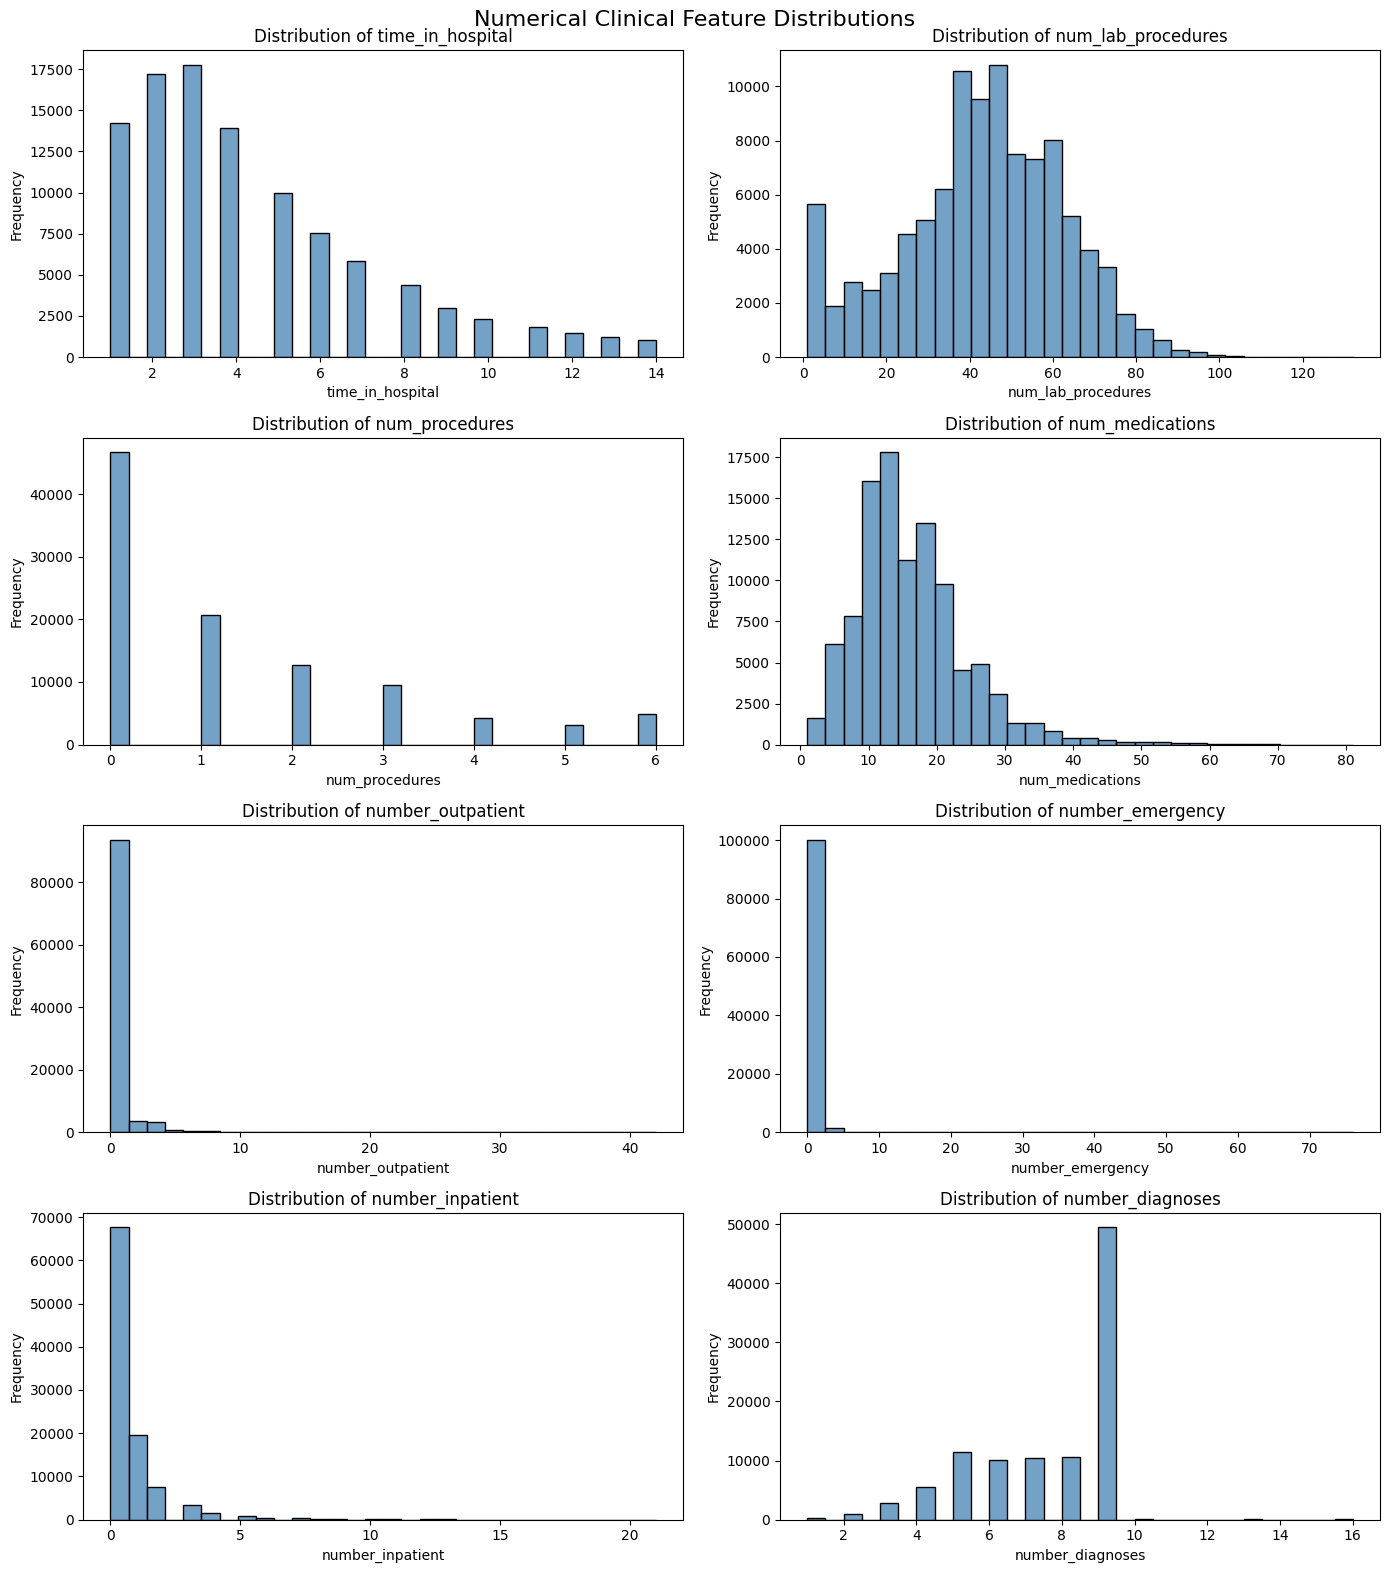

In [13]:
# ============================================================
# 5. NUMERICAL FEATURE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 16)
)

axes = axes.flatten()

for i, col in enumerate(numerical_columns):

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "Numerical Clinical Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Numerical outlier analysis

In [14]:
# ============================================================
# 6. IQR OUTLIER ANALYSIS
# ============================================================

outlier_results = []

for col in numerical_columns:

    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((series < lower) | (series > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": outliers,
        "Outlier %": round(
            outliers / len(series) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        "Outlier %",
        ascending=False
    )
)

,Feature,Outlier Count,Outlier %
4,number_outpatient,16739,16.45
5,number_emergency,11383,11.19
6,number_inpatient,7049,6.93
2,num_procedures,4954,4.87
3,num_medications,2557,2.51
0,time_in_hospital,2252,2.21
7,number_diagnoses,281,0.28
1,num_lab_procedures,143,0.14


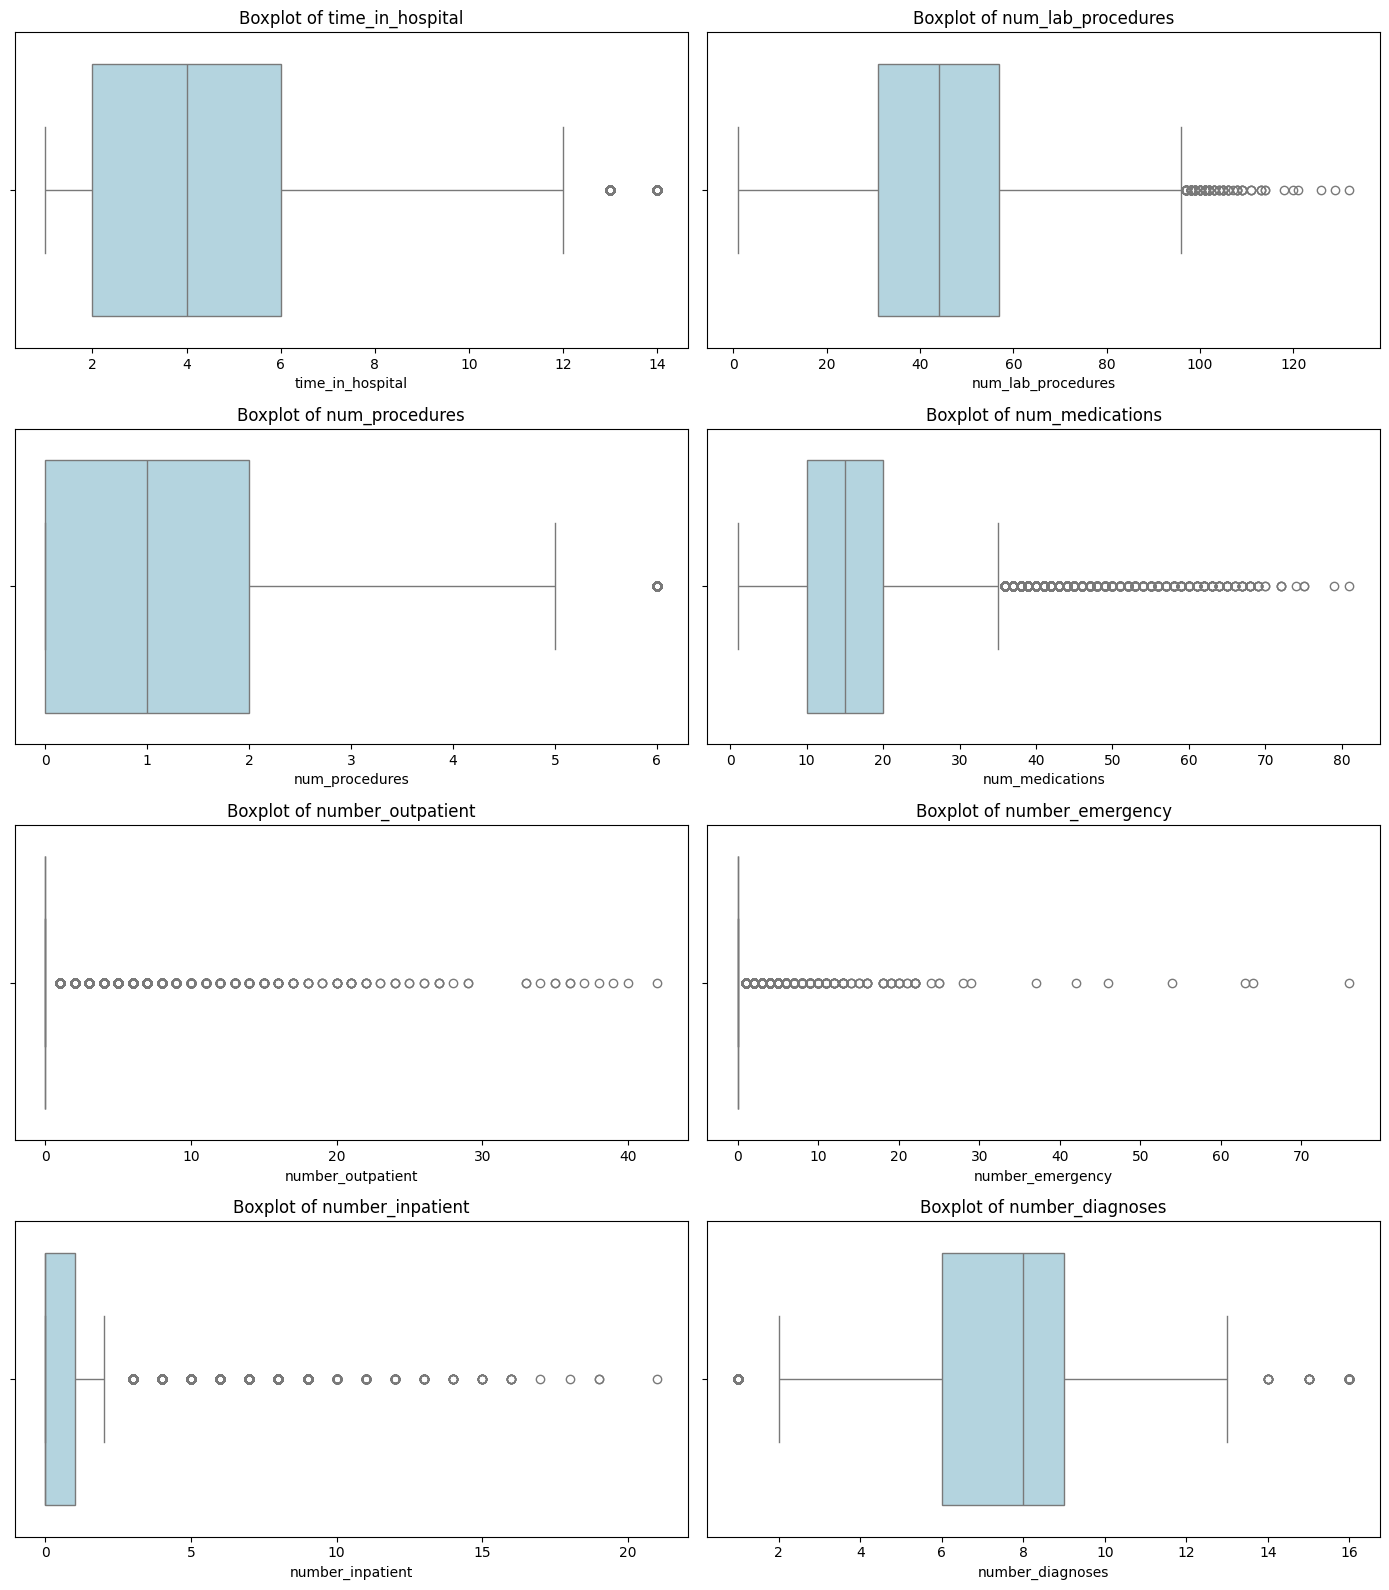

In [15]:
# ============================================================
# 7. NUMERICAL BOXPLOTS
# ============================================================

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 16)
)

axes = axes.flatten()

for i, col in enumerate(numerical_columns):

    sns.boxplot(
        x=df[col],
        ax=axes[i],
        color="lightblue"
    )

    axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

## Categorical feature distributions

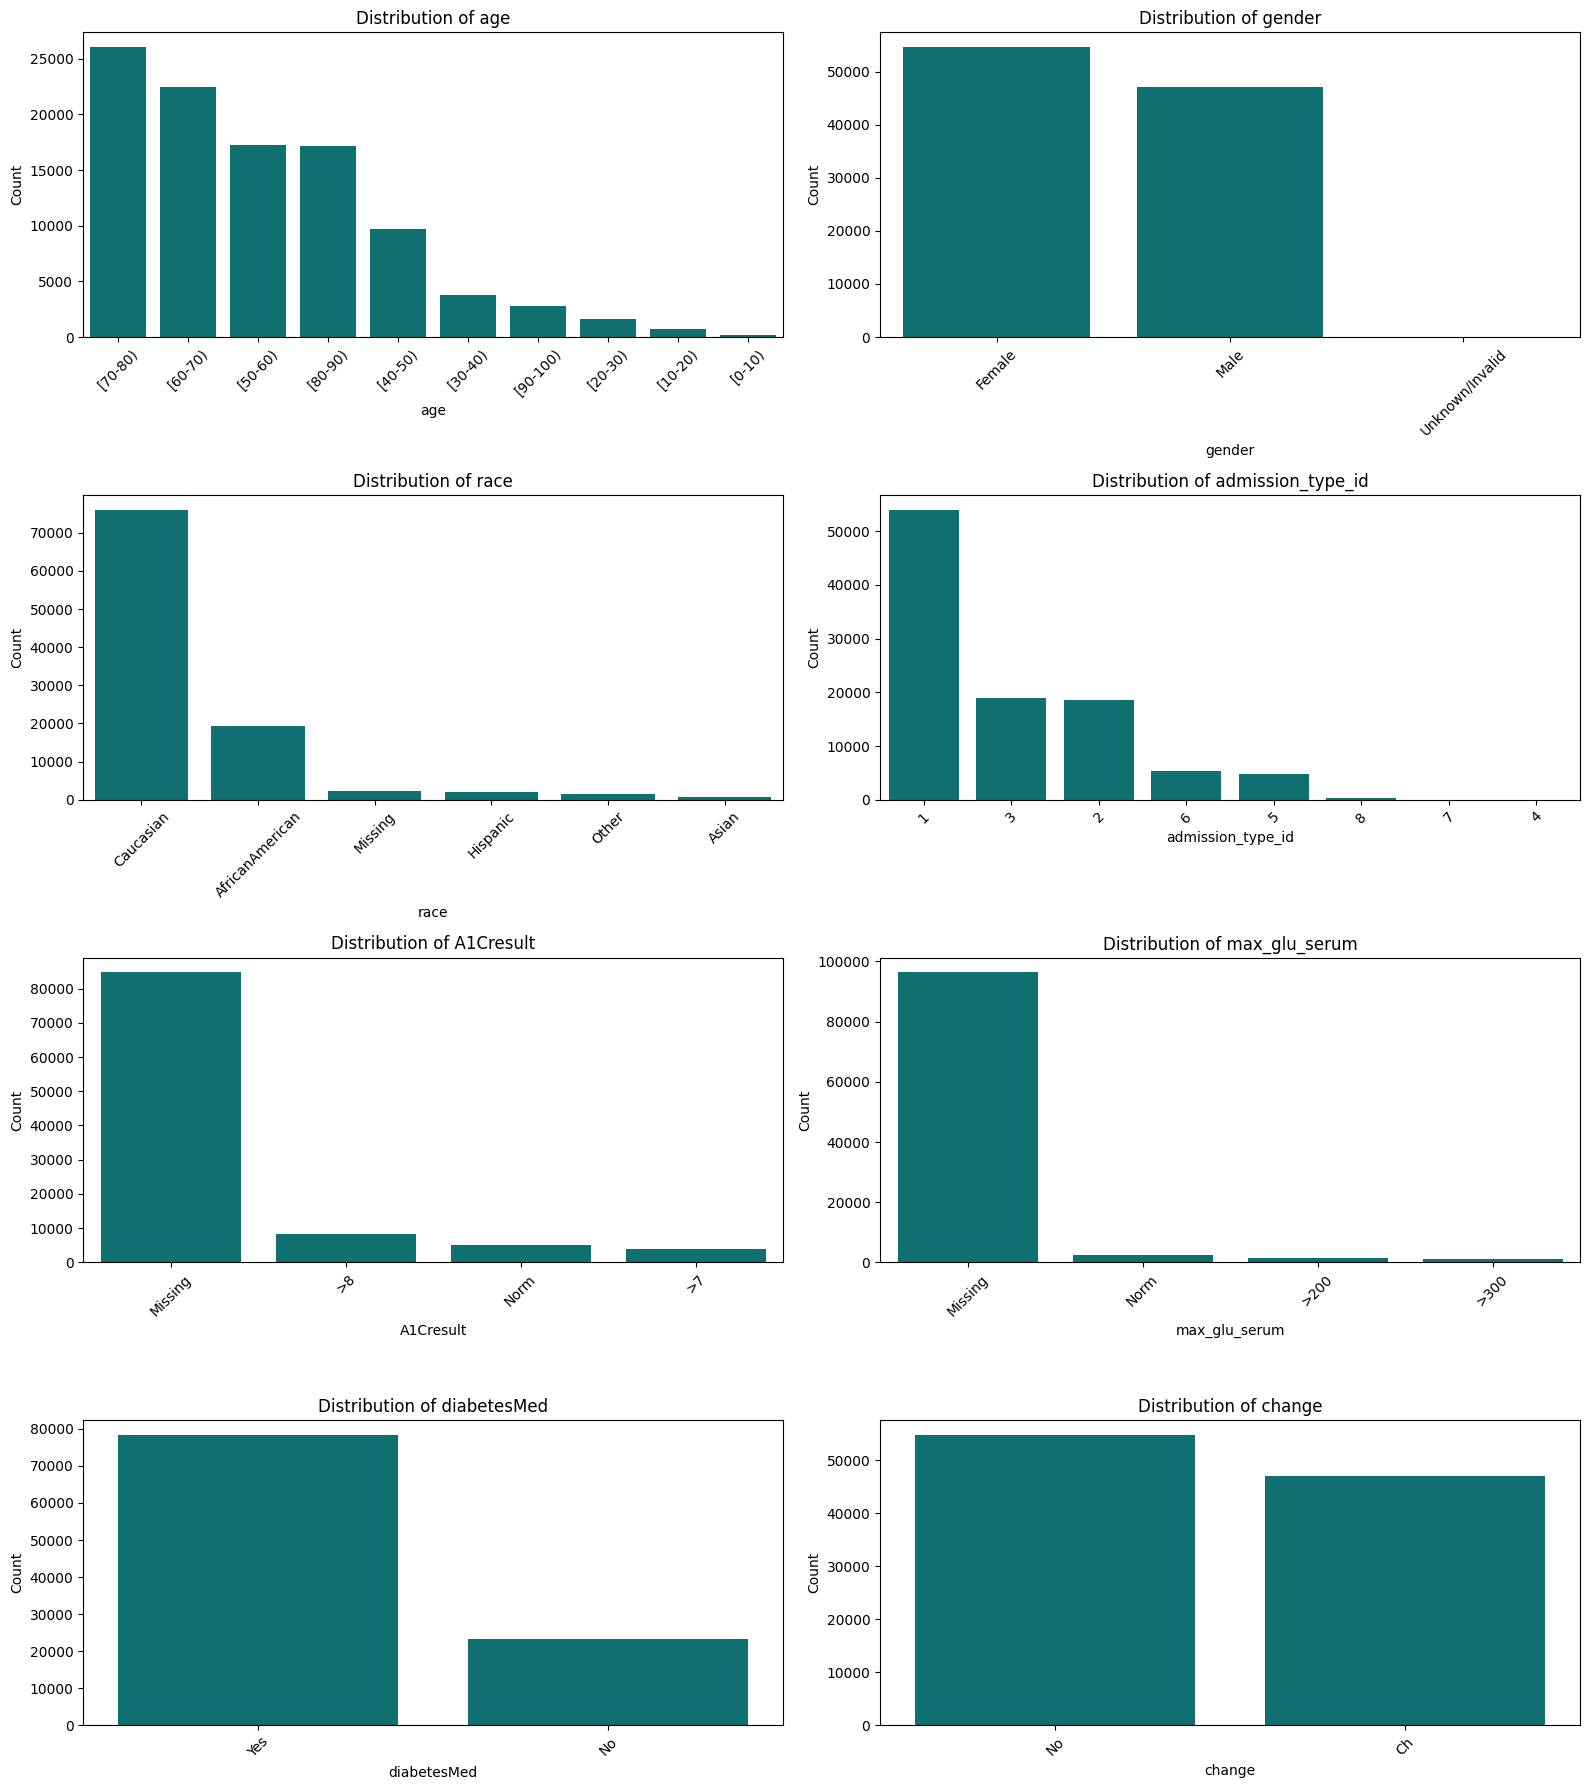

In [16]:
# ============================================================
# 8. CATEGORICAL FEATURE DISTRIBUTIONS
# ============================================================

selected_categorical = [
    "age",
    "gender",
    "race",
    "admission_type_id",
    "A1Cresult",
    "max_glu_serum",
    "diabetesMed",
    "change"
]

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for i, col in enumerate(selected_categorical):

    counts = (
        df[col]
        .fillna("Missing")
        .astype(str)
        .value_counts()
    )

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=axes[i],
        color="teal"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(
        axis="x",
        rotation=45
    )

    axes[i].set_ylabel("Count")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

## Target distribution and class imbalance

,Count,Percentage
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


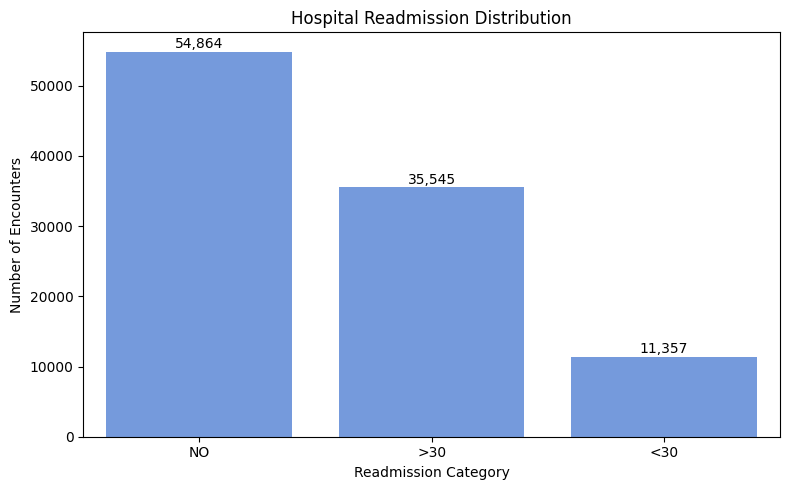

In [17]:
# ============================================================
# 9. READMISSION TARGET DISTRIBUTION
# ============================================================

target_counts = (
    df["readmitted"]
    .value_counts()
    .reindex(["NO", ">30", "<30"])
)

target_percent = (
    target_counts / target_counts.sum() * 100
)

display(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
}))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=target_counts.index,
    y=target_counts.values,
    color="cornflowerblue"
)

for i, count in enumerate(target_counts.values):
    ax.text(
        i,
        count + 500,
        f"{count:,}",
        ha="center"
    )

plt.title("Hospital Readmission Distribution")
plt.xlabel("Readmission Category")
plt.ylabel("Number of Encounters")

plt.tight_layout()
plt.show()

,Count,Percentage
Not readmitted within 30 days,90409,88.84
Readmitted within 30 days,11357,11.16


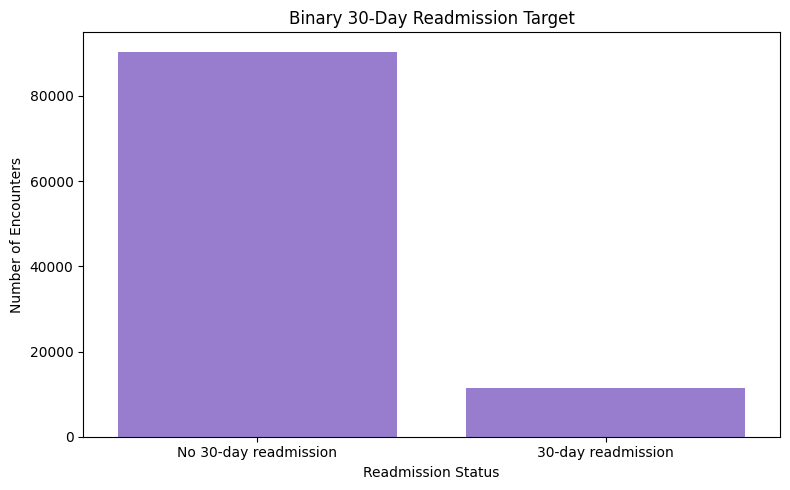

In [18]:
# ============================================================
# 10. BINARY READMISSION TARGET ANALYSIS
# ============================================================

readmitted_30 = (
    df["readmitted"] == "<30"
).astype(int)

binary_counts = (
    readmitted_30
    .value_counts()
    .sort_index()
)

binary_percent = (
    readmitted_30
    .value_counts(normalize=True)
    .sort_index() * 100
)

binary_summary = pd.DataFrame({
    "Count": binary_counts,
    "Percentage": binary_percent.round(2)
})

binary_summary.index = [
    "Not readmitted within 30 days",
    "Readmitted within 30 days"
]

display(binary_summary)

plt.figure(figsize=(8, 5))

sns.countplot(
    x=readmitted_30,
    color="mediumpurple"
)

plt.xticks(
    [0, 1],
    ["No 30-day readmission", "30-day readmission"]
)

plt.title("Binary 30-Day Readmission Target")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Encounters")

plt.tight_layout()
plt.show()

## Numerical feature correlations

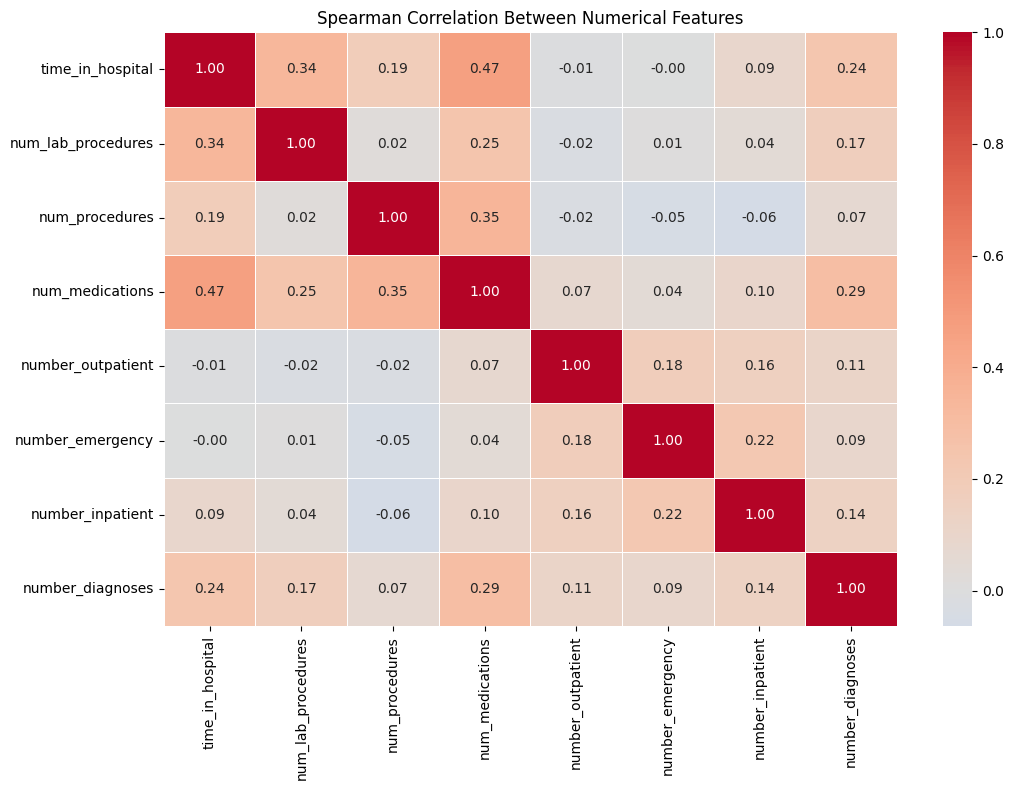

In [19]:
# ============================================================
# 11. NUMERICAL CORRELATION ANALYSIS
# ============================================================

correlation_matrix = (
    df[numerical_columns]
    .corr(method="spearman")
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation Between Numerical Features")

plt.tight_layout()
plt.show()

## Clinical features versus readmission

,age,mean,count,rate_percent
0,[0-10),0.018634,161,1.863354
1,[10-20),0.057887,691,5.788712
2,[20-30),0.142426,1657,14.242607
3,[30-40),0.112318,3775,11.231788
4,[40-50),0.106040,9685,10.604027
5,[50-60),0.096662,17256,9.666203
6,[60-70),0.111284,22483,11.128408
7,[70-80),0.117731,26068,11.773055
8,[80-90),0.120835,17197,12.083503
9,[90-100),0.110992,2793,11.099177


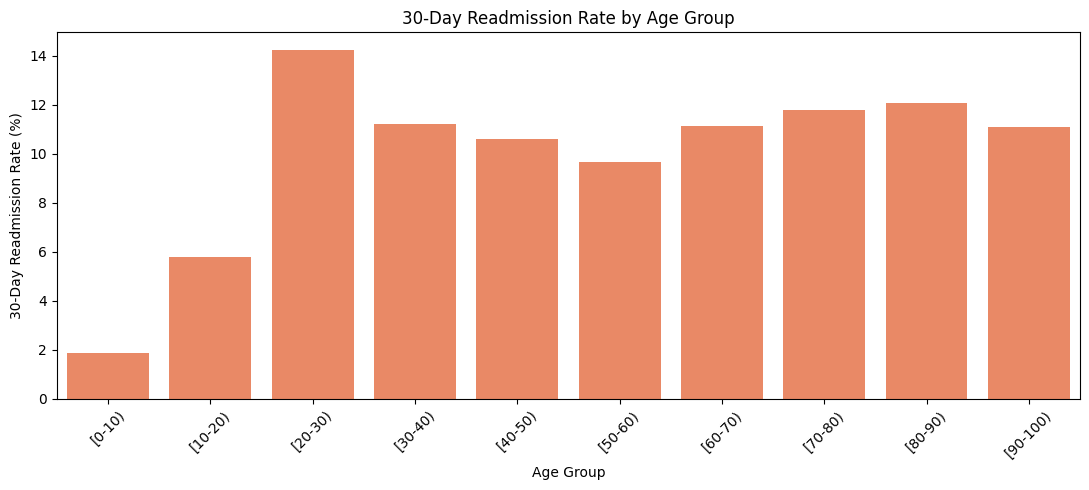

In [20]:
# ============================================================
# 12. READMISSION RATE BY AGE GROUP
# ============================================================

eda_view = df.copy()

eda_view["readmitted_30"] = (
    eda_view["readmitted"] == "<30"
).astype(int)

age_readmission = (
    eda_view
    .groupby("age", observed=True)["readmitted_30"]
    .agg(["mean", "count"])
    .reset_index()
)

age_readmission["rate_percent"] = (
    age_readmission["mean"] * 100
)

display(age_readmission)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=age_readmission,
    x="age",
    y="rate_percent",
    color="coral"
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

,time_in_hospital,mean,count,rate_percent
0,1,0.081785,14208,8.178491
1,2,0.099396,17224,9.939619
2,3,0.106668,17756,10.666817
3,4,0.118070,13924,11.806952
4,5,0.120309,9966,12.030905
5,6,0.125879,7539,12.587876
6,7,0.128350,5859,12.834955
7,8,0.142337,4391,14.233660
8,9,0.137242,3002,13.724184
9,10,0.143467,2342,14.346712


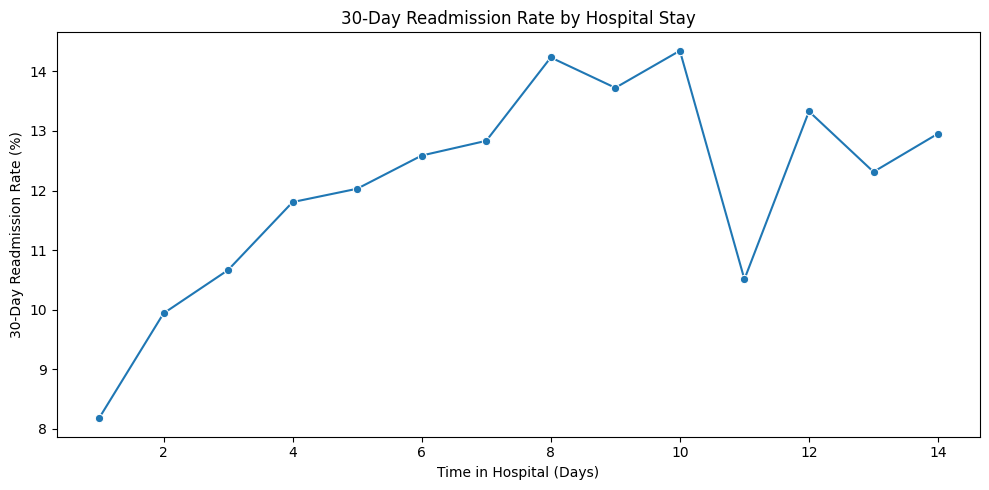

In [21]:
# ============================================================
# 13. READMISSION RATE BY LENGTH OF STAY
# ============================================================

stay_readmission = (
    eda_view
    .groupby("time_in_hospital")["readmitted_30"]
    .agg(["mean", "count"])
    .reset_index()
)

stay_readmission["rate_percent"] = (
    stay_readmission["mean"] * 100
)

display(stay_readmission)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=stay_readmission,
    x="time_in_hospital",
    y="rate_percent",
    marker="o"
)

plt.title("30-Day Readmission Rate by Hospital Stay")
plt.xlabel("Time in Hospital (Days)")
plt.ylabel("30-Day Readmission Rate (%)")

plt.tight_layout()
plt.show()

,number_inpatient,mean,count,rate_percent
0,0,0.084371,67630,8.437084
1,1,0.129245,19521,12.924543
2,2,0.174333,7566,17.433254
3,3,0.202873,3411,20.287306
4,4,0.236128,1622,23.612824
5,5,0.314039,812,31.403941
6,6,0.345833,480,34.583333
7,7,0.354478,268,35.447761
8,8,0.443709,151,44.370861
9,9,0.423423,111,42.342342


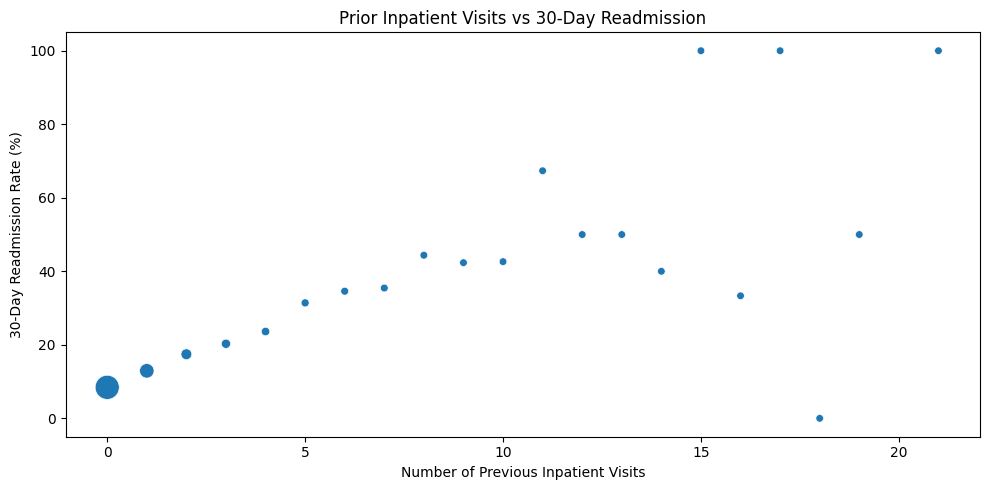

In [22]:
# ============================================================
# 14. PRIOR INPATIENT VISITS VS READMISSION
# ============================================================

inpatient_readmission = (
    eda_view
    .groupby("number_inpatient")["readmitted_30"]
    .agg(["mean", "count"])
    .reset_index()
)

inpatient_readmission["rate_percent"] = (
    inpatient_readmission["mean"] * 100
)

display(inpatient_readmission.head(20))

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=inpatient_readmission,
    x="number_inpatient",
    y="rate_percent",
    size="count",
    sizes=(30, 300),
    legend=False
)

plt.title("Prior Inpatient Visits vs 30-Day Readmission")
plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("30-Day Readmission Rate (%)")

plt.tight_layout()
plt.show()

## High-cardinality categorical features

,Feature,Unique Categories
0,diag_3,789
1,diag_2,748
2,diag_1,716
3,medical_specialty,72
4,discharge_disposition_id,26
5,admission_source_id,17
6,payer_code,17
7,age,10
8,weight,9
9,admission_type_id,8



High-cardinality categorical features:


,0
diag_3,789
diag_2,748
diag_1,716
medical_specialty,72


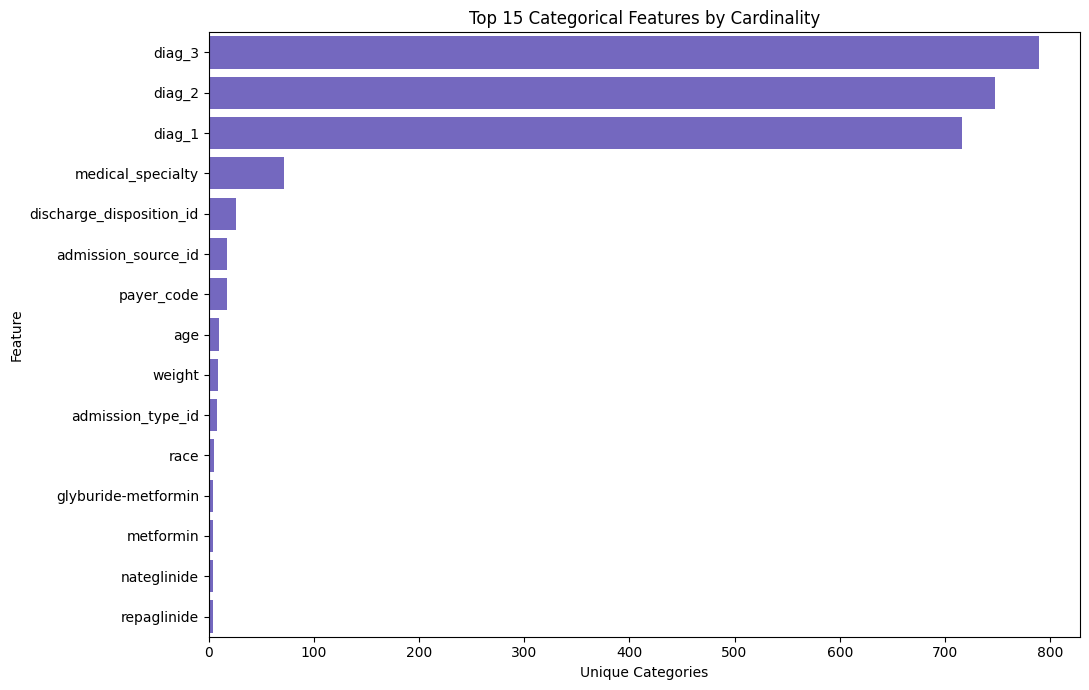

In [23]:
# ============================================================
# 15. CATEGORICAL CARDINALITY ANALYSIS
# ============================================================

cardinality = (
    df[categorical_columns]
    .nunique(dropna=True)
    .sort_values(ascending=False)
)

cardinality_df = pd.DataFrame({
    "Feature": cardinality.index,
    "Unique Categories": cardinality.values
})

display(cardinality_df)

high_cardinality = cardinality[
    cardinality > 50
]

print("\nHigh-cardinality categorical features:")
display(high_cardinality)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=cardinality_df.head(15),
    x="Unique Categories",
    y="Feature",
    color="slateblue"
)

plt.title("Top 15 Categorical Features by Cardinality")
plt.tight_layout()
plt.show()

## Missingness versus readmission

,Feature,Status,Count,Readmission Rate (%)
0,weight,Observed,3197,11.17
1,weight,Missing,98569,11.16
2,max_glu_serum,Observed,5346,12.36
3,max_glu_serum,Missing,96420,11.09
4,A1Cresult,Observed,17018,9.85
5,A1Cresult,Missing,84748,11.42
6,medical_specialty,Observed,51817,10.76
7,medical_specialty,Missing,49949,11.57
8,payer_code,Observed,61510,10.94
9,payer_code,Missing,40256,11.49


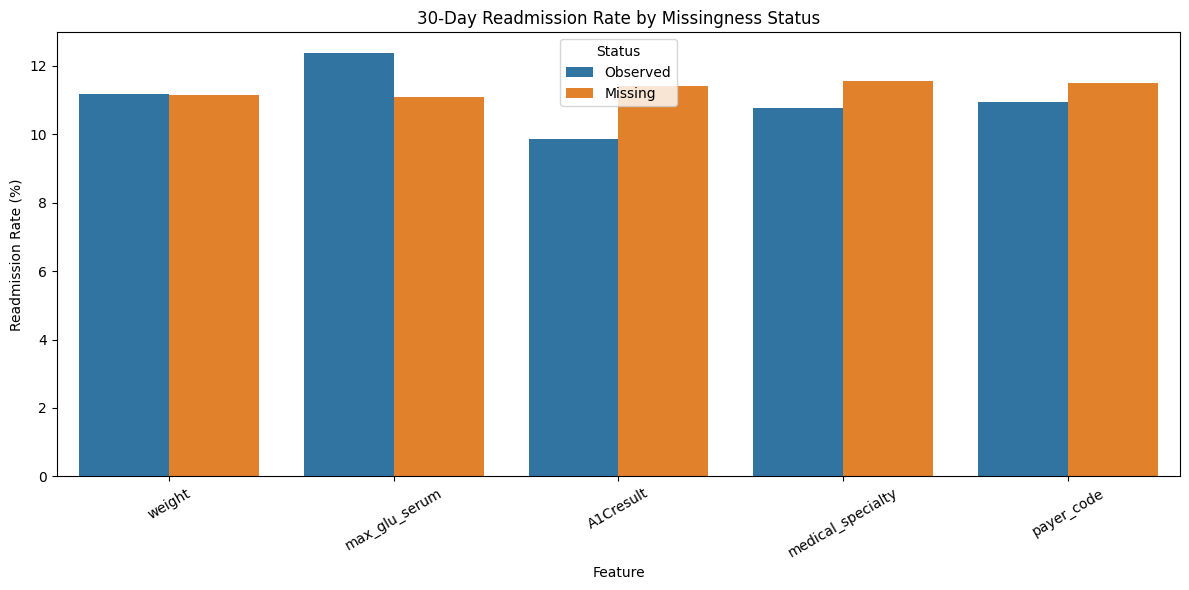

In [24]:
# ============================================================
# 16. MISSINGNESS AND READMISSION
# ============================================================

missingness_features = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code"
]

missingness_results = []

for col in missingness_features:

    missing_flag = eda_view[col].isna()

    for status in [False, True]:

        subset = eda_view.loc[
            missing_flag == status,
            "readmitted_30"
        ]

        if len(subset) == 0:
            continue

        missingness_results.append({
            "Feature": col,
            "Status": "Missing" if status else "Observed",
            "Count": len(subset),
            "Readmission Rate (%)": round(
                subset.mean() * 100, 2
            )
        })

missingness_results_df = pd.DataFrame(
    missingness_results
)

display(missingness_results_df)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missingness_results_df,
    x="Feature",
    y="Readmission Rate (%)",
    hue="Status"
)

plt.title("30-Day Readmission Rate by Missingness Status")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Patient identifiers and repeated encounters

The UCI loader stores `encounter_id` and `patient_nbr` separately from the modeling features. Inspect identifiers **without adding them as model predictors**. A row-count check alone does not establish alignment, so the following cell also checks indices. Patient-group splitting will be performed in preprocessing.

In [ ]:
ids = diabetes.data.ids.copy()
print("Identifier columns:", ids.columns.tolist())
print("Identifier shape:", ids.shape)
display(ids.head())

required_ids = {"encounter_id", "patient_nbr"}
assert required_ids.issubset(ids.columns), "Required identifiers unavailable"
assert len(ids) == len(df), "ID and feature row counts differ"
assert ids.index.equals(df.index), "ID and feature indices do not align"
assert ids["patient_nbr"].notna().all(), "Missing patient IDs"
assert ids["encounter_id"].is_unique, "Encounter IDs are not unique"

patient_counts = ids["patient_nbr"].value_counts()
repeat_patient_count = int((patient_counts > 1).sum())
repeat_encounter_count = int(patient_counts[patient_counts > 1].sum())

patient_audit = pd.DataFrame({
    "Measure": ["Encounters", "Unique patients", "Patients with >1 encounter",
                "Encounters belonging to repeat patients", "Repeat-encounter share (%)",
                "Maximum encounters per patient"],
    "Value": [len(df), ids["patient_nbr"].nunique(), repeat_patient_count,
              repeat_encounter_count, round(100 * repeat_encounter_count / len(df), 2),
              int(patient_counts.max())]
})
display(patient_audit)
print("Split policy: group by patient_nbr; exclude identifiers from generator inputs.")

## Discharge disposition: exclusion audit

The codes `[11, 13, 14, 19, 20, 21]` are **candidate** death/hospice exclusions. The UCI variable description does not spell out each code meaning. Verify the mapping against the dataset's discharge-disposition documentation before applying any exclusion. This cell only audits the counts and outcomes; it does not filter `df`.

In [26]:
discharge_metadata = diabetes.variables.loc[
    diabetes.variables["name"].eq("discharge_disposition_id")
]
display(discharge_metadata)

candidate_exclusion_codes = [11, 13, 14, 19, 20, 21]
code_counts = (df["discharge_disposition_id"]
               .value_counts(dropna=False)
               .reindex(candidate_exclusion_codes, fill_value=0)
               .rename_axis("discharge_disposition_id")
               .reset_index(name="encounters"))
display(code_counts)

candidate_mask = df["discharge_disposition_id"].isin(candidate_exclusion_codes)
print(f"Candidate exclusions: {candidate_mask.sum():,} / {len(df):,} "
      f"({candidate_mask.mean()*100:.2f}%)")
print("Readmission labels within candidate exclusions:")
display(df.loc[candidate_mask, "readmitted"].value_counts(dropna=False))
print("Remaining encounters if all candidates are later confirmed:",
      int((~candidate_mask).sum()))

,name,role,type,demographic,description,units,missing_values
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no


,discharge_disposition_id,encounters
0,11,1642
1,13,399
2,14,372
3,19,8
4,20,2
5,21,0


Candidate exclusions: 2,423 / 101,766 (2.38%)
Readmission labels within candidate exclusions:


,count
readmitted,
NO,2337
<30,43
>30,43


Remaining encounters if all candidates are later confirmed: 99343


## Data Handling Decisions for Preprocessing

**Decisions for the next preprocessing stage (not executed here):**

1. **Patient overlap:** The dataset contains 71,518 unique patients across 101,766 encounters. Among these, 16,773 patients have multiple encounters, accounting for 46.21% of all encounters. Use `patient_nbr` with `GroupShuffleSplit` to prevent patient overlap between training and testing datasets. Verify that no patient occurs in both sets and compare target prevalence. Exclude `patient_nbr` and `encounter_id` from generative model features.

2. **Target variable:** Create a binary target, `readmitted_30`, where `1` represents readmission within 30 days (`<30`) and `0` represents readmission after 30 days (`>30`) or no recorded readmission (`NO`). The original three-class `readmitted` variable will be retained for EDA but excluded from the generative modeling dataset after binary target creation.

3. **Discharge outcomes:** Exclude encounters with discharge disposition codes `11, 13, 14, 19, 20, 21`, corresponding to death-related or hospice discharges, as verified against the dataset's `IDs_mapping.csv`. These codes account for 2,423 encounters (2.38%), leaving 99,343 encounters before additional cleaning. The original and filtered target distributions will be compared and the exclusion documented.

4. **Missing-value handling:** Drop `weight` because approximately 96.86% of its values are missing. Retain `A1Cresult` and `max_glu_serum`, representing missing values using the explicit category `Not_recorded` rather than assuming that every missing result indicates a test was not performed. Handle other missing categorical values using a `Missing` category where appropriate. The original study by Strack et al. (2014) reported HbA1c testing in 18.4% of encounters in its analyzed cohort.

5. **Categorical semantics:** Treat `admission_type_id`, `discharge_disposition_id`, and `admission_source_id` as categorical features rather than continuous numerical variables. Exclude the three records with `Unknown/Invalid` gender values and document their removal.

6. **Uninformative features:** Remove the constant columns `examide` and `citoglipton`, as they contain no variation and provide no useful information for generative modeling.

7. **High-cardinality features:** Group diagnosis variables (`diag_1`, `diag_2`, `diag_3`) into broader clinical categories using a documented ICD-9 mapping that handles numeric, `V`, and `E` codes. Group rare `medical_specialty` categories into `Other`, using frequency thresholds learned from training data only.

8. **Skewed numerical features:** Retain highly skewed hospital utilization variables, including `number_emergency`, `number_outpatient`, and `number_inpatient`, during initial modeling. Assess how well the synthetic datasets reproduce their distributions and extreme values. Apply clipping only if justified, using thresholds learned exclusively from training data.

9. **Data leakage prevention:** Perform the patient-grouped train/test split before fitting any data-dependent preprocessing transformations. Fit imputers, encoders, scalers, rare-category mappings, and generative models using training data only. Apply fitted transformations unchanged to the held-out test dataset. The real test set will be reserved for downstream utility evaluation.

10. **Reproducibility:** Record random seeds, dataset filtering criteria, preprocessing transformations, model configurations, software versions, training times, and synthetic sample sizes. Save processed datasets and experimental outputs to persistent storage to support reproducibility.

**Scope:** This notebook focuses on exploratory data analysis and data-quality auditing. No records or features have been removed during EDA. The documented preprocessing decisions will be implemented in `src/preprocessing.py`, and the resulting datasets will be used for the comparative evaluation of TVAE, CTGAN, and TabDDPM.

## Save EDA summaries (optional)

In [27]:
from pathlib import Path

output_dir = Path("eda_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

feature_summary.to_csv(output_dir / "feature_summary.csv")
missing_summary.to_csv(output_dir / "missing_summary.csv")
numerical_summary.to_csv(output_dir / "numerical_summary.csv")
cardinality_df.to_csv(output_dir / "categorical_cardinality.csv", index=False)
outlier_df.to_csv(output_dir / "outlier_summary.csv", index=False)
missingness_results_df.to_csv(output_dir / "missingness_readmission.csv", index=False)
patient_audit.to_csv(output_dir / "patient_audit.csv", index=False)
code_counts.to_csv(output_dir / "candidate_discharge_codes.csv", index=False)

print("Saved EDA summary tables to:", output_dir.resolve())
print("Note: Colab runtime files are temporary. Copy these to Drive if needed.")

Saved EDA summary tables to: /content/eda_outputs
Note: Colab runtime files are temporary. Copy these to Drive if needed.


## Final EDA summary

In [28]:
print("=" * 60)
print("FINAL EDA SUMMARY")
print("=" * 60)
print(f"Encounters: {len(df):,} | Columns: {df.shape[1]}")
print(f"Unique patients: {ids['patient_nbr'].nunique():,}")
print(f"Repeat-patient encounter share: {repeat_encounter_count / len(df) * 100:.2f}%")
print(f"Exact duplicate feature rows: {df.duplicated().sum():,}")
print(f"Columns with missing values: {(df.isna().sum() > 0).sum()}")
print("Constant columns:", constant_columns)
print("Features with >50% missingness:")
print((df.isna().mean().mul(100)).loc[lambda s: s > 50].round(2))
print(f"30-day readmission prevalence: {readmitted_30.mean() * 100:.2f}%")
print(f"Candidate discharge exclusions (unverified mapping): {candidate_mask.sum():,}")
print("EDA complete; preprocessing has not yet been applied.")

FINAL EDA SUMMARY
Encounters: 101,766 | Columns: 48
Unique patients: 71,518
Repeat-patient encounter share: 46.21%
Exact duplicate feature rows: 0
Columns with missing values: 9
Constant columns: ['examide', 'citoglipton']
Features with >50% missingness:
weight           96.86
max_glu_serum    94.75
A1Cresult        83.28
dtype: float64
30-day readmission prevalence: 11.16%
Candidate discharge exclusions (unverified mapping): 2,423
EDA complete; preprocessing has not yet been applied.


## EDA Conclusions

The UCI Diabetes 130-US Hospitals dataset contains **101,766 hospital encounters and 48 loaded columns**, including the readmission target. It contains numerical hospital utilization measures, demographic variables, medication categories, diagnosis codes, and administrative categorical features. Approximately **11.16% of encounters** belong to the `<30` readmission category, indicating substantial class imbalance for the downstream prediction task.

The dataset presents several challenges for synthetic clinical data generation, including missing values, high-cardinality categorical features, and skewed numerical distributions. The `weight` variable has approximately 96.86% missingness, while `max_glu_serum` and `A1Cresult` have approximately 94.75% and 83.28% missingness, respectively. Missing laboratory results will be preserved as an explicit `Not_recorded` category during preprocessing rather than automatically removing these clinically relevant features.

**Patient-level analysis** identified 71,518 unique patients across 101,766 encounters. Among these, 16,773 patients have multiple encounters, accounting for **46.21% of all encounters**. Therefore, patient-grouped train/test splitting will be used to prevent patient overlap and support reliable evaluation on previously unseen patients.

**Discharge disposition analysis** identified 2,423 encounters (2.38%) with codes `11, 13, 14, 19, 20, 21`. These codes were confirmed as death-related or hospice discharge categories using the dataset's discharge-disposition mapping. These encounters will be excluded during preprocessing, and the exclusion criteria will be documented.

Additional preprocessing decisions include removing constant features, addressing invalid categorical values, grouping high-cardinality diagnosis codes, converting integer-coded administrative variables into categorical features, and creating a binary `readmitted_30` target (`<30` = 1; otherwise = 0).

**No records or features were removed or modified during EDA.** The next stage will apply the documented cohort exclusions, create a patient-grouped train/test split, and fit data-dependent preprocessing transformations using training data only. The resulting datasets will support a consistent comparison of **TVAE, CTGAN, and TabDDPM** across statistical fidelity, machine learning utility, and privacy risk.